# NHL: предсказать успешность команды в следующем сезоне

**Тестовое задание • 100 баллов**

Вы аналитик, которому после окончания сезона нужно оценить перспективы команды
на следующий год. Соберите таблицу с учебного сайта
[Scrape This Site - Hockey Teams](https://www.scrapethissite.com/pages/forms/),
изучите данные и постройте модель классификации.
В работе оцениваются корректность исследования и обоснованность решений.

Ориентир времени: 6-10 часов (знание хоккея не требуется).
Можно обращаться к документации и пользоваться вспомогательными инструментами.
Укажите, чем пользовались; отвечайте за правильность и понимание сданной работы.
Подтверждайте ответы результатами из своего ноутбука.

## Что сдавать

Выполненный IPynb с видимыми результатами и ответами и исходный `data/hockey_raw.csv` разместите на платформе githib.com.
Укажите имя, дату и использованные источники и инструменты в README.

## Что предсказывает модель

Одна строка признаков описывает команду в сезоне `t`.
`target=1`, если доля побед той же команды в сезоне `t+1` строго выше медианной
доли побед всех команд в сезоне `t+1`. В остальных случаях `target=0`.

Медиану считайте по полной исходной таблице будущего года до отбора пар.
В пары включайте одинаковые названия команды с разницей меток сезонов ровно в один год.
Строки без пары исключайте и учитывайте в описании данных.
Будущий `win_rate` и будущая медиана используются для построения target и анализа
готовых прогнозов. Признаки модели должны быть известны после сезона `t`.

## Схема проверки

Делите данные по году целевого сезона:

| Часть | target_year | Назначение |
|---|---|---|
| train | не позднее 2005 | Подготовка данных и обучение |
| validation | 2006-2008 | Сравнение вариантов и выбор решения |
| test | 2009-2011 | Одна итоговая оценка выбранного решения |

Основная метрика: ROC-AUC по вероятности класса 1.
На итоговом этапе также используйте F1 и accuracy при пороге 0.5.
Финальный test используйте после выбора решения на validation.

## Как оценивается работа

| Область | Баллы |
|---|---:|
| Сбор и понимание данных | 15 |
| Построение задачи и корректность проверки | 20 |
| Исследовательский анализ | 20 |
| Модели и эксперименты | 25 |
| Итоговая оценка и анализ ошибок | 15 |
| Ясность и воспроизводимость | 5 |
| **Всего** | **100** |

Ниже перечислены обязательные этапы работы. Внутри них вы самостоятельно выбираете
исследовательские вопросы, графики, признаки, обработку данных, эксперимент и способ
разбора ошибок. Оценивается качество решений, а не совпадение с эталонным маршрутом.
Сложность метода сама по себе не даёт преимущества. Корректный эксперимент может
получить полный балл и в случае отсутствия улучшения.

## Требования к сбору

Итоговая исходная таблица должна иметь столбцы `team`, `year`, `wins`, `losses`,
`ot_losses`, `win_rate`, `goals_for`, `goals_against`, `goal_diff`.
Самостоятельно исследуйте страницу и определите способ получения всей таблицы.

**Автор:** Погорелов Даниил Андреевич  
**Дата исходной работы:** 09.10.2026  
**Дата доработки и повторной проверки:** 13.10.2026  
**Источник данных:** https://www.scrapethissite.com/pages/forms/  
**Инструменты:** Python, pandas, numpy, matplotlib, scikit-learn, lxml; формат работы — Jupyter Notebook. ChatGPT использован для рецензирования и доработки этой версии.  
**Окружение повторной проверки:** Python 3.12.14; версии библиотек записаны в `requirements.txt`.


In [1]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone
from sklearn.metrics import f1_score, accuracy_score

## Раздел 1. Сбор и понимание данных: 15 баллов

### 1.1. Соберите и сохраните данные

Соберите все страницы сайта в одну таблицу с указанными девятью столбцами.
Сохраните исходную выгрузку в `data/hockey_raw.csv`. Укажите URL и дату сбора,
число обработанных страниц и число строк. Покажите, как проверили,
что сбор не ограничился первой страницей и при повторном анализе можно читать CSV.

**Режим работы.** Для повторного анализа используется сохранённый `data/hockey_raw.csv`. Сбор с сайта выделен в отдельную ячейку и по умолчанию отключён. Для новой выгрузки установите `COLLECT_DATA = True`, выполните ячейку сбора, затем чтения CSV. Новая выгрузка заменяет сохранённый файл.


In [2]:
COLLECT_DATA = False
DATA_PATH = Path("data/hockey_raw.csv")
url = "https://www.scrapethissite.com/pages/forms/?per_page=1000"
columns = [
    "team", "year", "wins", "losses", "ot_losses",
    "win_rate", "goals_for", "goals_against", "goal_diff"
]

# Отдельный этап сбора; при обычном запуске обращений к сайту нет.
if COLLECT_DATA:
    downloaded = pd.read_html(url, storage_options={"User-Agent": "Mozilla/5.0"})[0]
    assert downloaded.shape[1] == len(columns), "Изменилась структура таблицы сайта"
    downloaded.columns = columns
    DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    downloaded.to_csv(DATA_PATH, index=False)
    print("Сбор завершён: одна страница с per_page=1000; строк:", len(downloaded))
else:
    print("Сбор отключён. Следующая ячейка читает сохранённый CSV.")


Сбор отключён. Следующая ячейка читает сохранённый CSV.


In [3]:
# Повторный анализ: загрузка только из сохранённого файла.
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        "Не найден data/hockey_raw.csv. Скачайте папку data из репозитория "
        "или включите COLLECT_DATA и выполните предыдущую ячейку."
    )
df = pd.read_csv(DATA_PATH)
assert list(df.columns) == columns, "Столбцы CSV не соответствуют ожидаемой схеме"
print(df.shape)
display(df.head())


(582, 9)


,team,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff
0,Boston Bruins,1990,44,24,NaN,0.550,299,264,35
1,Buffalo Sabres,1990,31,30,NaN,0.388,292,278,14
2,Calgary Flames,1990,46,26,NaN,0.575,344,263,81
3,Chicago Blackhawks,1990,49,23,NaN,0.613,284,211,73
4,Detroit Red Wings,1990,34,38,NaN,0.425,273,298,-25


**Ответ 1.1:**

Данные собраны 09.10.2026 с сайта [https://www.scrapethissite.com/pages/forms/](https://www.scrapethissite.com/pages/forms/). С помощью параметра `per_page=1000` вся таблица получена одним запросом: обработана одна страница, получено **582 строки и 9 столбцов** за сезоны 1990–2011.\
На сайте при стандартной пагинации 24 страницы: первые 23 содержат по 25 строк, последняя — 7. Ожидаемое количество строк: **23 × 25 + 7 = 582**, что совпадает с результатом `df.shape`.\
Таблица сохранена в `data/hockey_raw.csv`. При повторном анализе данные можно загрузить из сохранённого файла строчкой `pd.read_csv("data/hockey_raw.csv")` без обращения к сайту

В комплект включена повторная выгрузка от 13.10.2026: 582 строки и 9 столбцов. При проверке на ней итоговые метрики совпали с исходными. По умолчанию этап сбора отключён (`COLLECT_DATA=False`), анализ читает `data/hockey_raw.csv`.


### 1.2. Проверьте качество таблицы

Изучите типы, пропуски и уникальность пары команда-год.
Добавьте не менее двух проверок согласованности, которые считаете важными
для последующего анализа. Покажите найденные особенности и обоснуйте
решения по их обработке. Сами проверки и способ представления результата выберите самостоятельно.

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 582 entries, 0 to 581
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   team           582 non-null    object 
 1   year           582 non-null    int64  
 2   wins           582 non-null    int64  
 3   losses         582 non-null    int64  
 4   ot_losses      358 non-null    float64
 5   win_rate       582 non-null    float64
 6   goals_for      582 non-null    int64  
 7   goals_against  582 non-null    int64  
 8   goal_diff      582 non-null    int64  
dtypes: float64(2), int64(6), object(1)
memory usage: 41.1+ KB


In [5]:
df.isna().sum()

team               0
year               0
wins               0
losses             0
ot_losses        224
win_rate           0
goals_for          0
goals_against      0
goal_diff          0
dtype: int64

In [6]:
df.duplicated(["team", "year"]).sum()

np.int64(0)

In [7]:
df[df['goal_diff'] == df['goals_for'] - df['goals_against']].shape[0]

582

In [8]:
df[df['win_rate'].between(0, 1)].shape[0]

582

In [9]:
df.groupby("year")["ot_losses"].count()

year
1990     0
1991     0
1992     0
1993     0
1994     0
1995     0
1996     0
1997     0
1998     0
1999    28
2000    30
2001    30
2002    30
2003    30
2005    30
2006    30
2007    30
2008    30
2009    30
2010    30
2011    30
Name: ot_losses, dtype: int64

**Ответ 1.2:**

В таблице 582 строки и 9 столбцов. Названия команд имеют тип `object`, год и основные счётчики — `int64`, `win_rate` и `ot_losses` — `float64`. Тип `ot_losses` связан с наличием пропусков.

Повторов пары команда–год нет. Обе проверки прошли все 582 строки: `goal_diff` равен `goals_for − goals_against`, а `win_rate` находится в диапазоне `[0, 1]`. Исправления этих значений не требуются.

В `ot_losses` обнаружено 224 пропуска: показатель отсутствует у всех команд за 1990–1998 годы. На этом этапе пропуски сохраняются, поскольку отсутствие значения не означает ноль поражений. В остальных столбцах пропусков нет.

Сезон 2004 отсутствует. При построении пар сезонов будем требовать разницу ровно в один год, чтобы не соединять 2003 с 2005.

## Раздел 2. Построение задачи и корректность проверки: 20 баллов

### 2.1. Постройте target

Соедините строку команды в сезоне `t` с той же командой ровно в сезоне `t+1`
и постройте target по определению задания. Покажите число полученных пар,
число и годы исключённых строк, а также число случаев равенства будущей медиане.
Проверьте расчёт вручную минимум на двух содержательно разных примерах.

In [10]:
future = df[["team", "year", "win_rate"]].rename(columns={"win_rate": "future_win_rate"})
future["year"] -= 1
pairs = df.merge(future, on=["team", "year"], how="left")

# Показываем строки без следующего сезона.
excluded = pairs[pairs["future_win_rate"].isna()]
print("Исключено строк:", len(excluded))
display(excluded.groupby("year").size())

# Оставляем только найденные пары.
pairs = pairs.dropna(subset=["future_win_rate"])
print("Получено пар:", len(pairs))

medians = df.groupby("year")["win_rate"].median()
pairs["future_median"] = (pairs["year"] + 1).map(medians)
pairs["target"] = (pairs["future_win_rate"] > pairs["future_median"]).astype(int)

print("Равенств медиане:", (pairs["future_win_rate"] == pairs["future_median"]).sum())
columns = ["team", "year", "future_win_rate", "future_median", "target"]
display(pairs[pairs["target"] == 1][columns].head(1))
display(pairs[pairs["target"] == 0][columns].head(1))

Исключено строк: 66


year
1992     1
1994     1
1995     1
1996     1
2003    30
2005     1
2010     1
2011    30
dtype: int64

Получено пар: 516
Равенств медиане: 23


,team,year,future_win_rate,future_median,target
0,Boston Bruins,1990,0.45,0.444,1


,team,year,future_win_rate,future_median,target
1,Buffalo Sabres,1990,0.388,0.444,0


**Ответ 2.1:**

Для каждой команды сезон `t` соединён с сезоном ровно `t+1` по одинаковому названию команды. Получено **516 пар**, исключено **66 строк** без следующего сезона: по одной за 1992, 1994, 1995, 1996, 2005 и 2010 годы, по 30 за 2003 и 2011 годы.

Медиана `win_rate` рассчитана для каждого будущего года по всей исходной таблице до исключения строк. `target = 1`, если будущая доля побед строго выше медианы, иначе `target = 0`. Найдено **23 случая равенства медиане** — им присвоен класс 0.

Ручная проверка:

- **Boston Bruins, 1990 → 1991:** будущая доля побед `0.450 > 0.444`, поэтому `target = 1`.
- **Buffalo Sabres, 1990 → 1991:** будущая доля побед `0.388 < 0.444`, поэтому `target = 0`.

Оба примера подтверждают правильность расчёта.

### 2.2. Подготовьте временную проверку

Разделите пары на train, validation и test по заданным границам target_year.
Покажите для каждой части фактические годы, размер и долю класса 1.
Назовите минимум два столбца, которые появились при построении target,
но недоступны модели в момент прогноза. Объясните, почему случайное перемешивание
строк отвечало бы на другой вопрос, чем выбранная временная схема.

In [11]:
pairs["target_year"] = pairs["year"] + 1

train = pairs[pairs["target_year"] <= 2005]
validation = pairs[pairs["target_year"].between(2006, 2008)]
test = pairs[pairs["target_year"].between(2009, 2011)]

for name, part in [("train", train), ("validation", validation), ("test", test)]:
    print(name)
    print("Годы:", sorted(part["target_year"].unique()))
    print("Строк:", len(part))
    print("Доля класса 1:", round(part["target"].mean(), 3))
    print()

train
Годы: [np.int64(1991), np.int64(1992), np.int64(1993), np.int64(1994), np.int64(1995), np.int64(1996), np.int64(1997), np.int64(1998), np.int64(1999), np.int64(2000), np.int64(2001), np.int64(2002), np.int64(2003)]
Строк: 338
Доля класса 1: 0.491

validation
Годы: [np.int64(2006), np.int64(2007), np.int64(2008)]
Строк: 89
Доля класса 1: 0.472

test
Годы: [np.int64(2009), np.int64(2010), np.int64(2011)]
Строк: 89
Доля класса 1: 0.472



**Ответ 2.2:**

Данные разделены по году целевого сезона `target_year = year + 1`:

- **Train:** 1991–2003 годы, 338 строк, доля класса 1 — 0.491.
- **Validation:** 2006–2008 годы, 89 строк, доля класса 1 — 0.472.
- **Test:** 2009–2011 годы, 89 строк, доля класса 1 — 0.472.

В train нет целевых сезонов 2004 и 2005: в исходных данных отсутствует 2004 год, поэтому соответствующие пары построить нельзя.

Столбцы `future_win_rate` и `future_median` недоступны в момент прогноза и не будут использоваться как признаки: они содержат информацию о будущем сезоне.

Временное разделение проверяет прогнозирование будущих сезонов по прошлым. Случайное перемешивание могло бы включить более поздние сезоны в обучение, а ранние — в проверку, поэтому отвечало бы на другой вопрос.

## Раздел 3. Исследовательский анализ: 20 баллов

### 3.1. Сформулируйте вопросы к данным

До построения основных графиков сформулируйте не менее двух собственных
исследовательских вопросов, связанных с будущей успешностью команд
или устройством данных. Для каждого запишите ожидаемый результат и объясните,
как ответ может повлиять на выбор признаков, обработку или интерпретацию модели.

**Ответ 3.1:**

1. **Связана ли текущая доля побед с успешностью в следующем сезоне?**  
   Ожидаю, что команды с высоким `win_rate` чаще получат `target = 1`. Подтверждение связи поможет обосновать использование `win_rate` как признака и простого ориентира для модели.

2. **Связана ли текущая разница голов с будущей успешностью?**  
   Ожидаю, что команды с положительным `goal_diff` чаще получат `target = 1`. Результат поможет оценить полезность разницы голов как признака.

3. **Связано ли число пропущенных голов с успешностью в следующем сезоне?**  
   Ожидаю, что команды с меньшим `goals_against` чаще получат `target = 1`. Если связь подтвердится, рассмотрю этот показатель как отдельный признак качества защиты.

Вопросы будут исследованы на train; обнаруженные связи не будут интерпретироваться как доказательство причинности.

### 3.2. Проведите исследовательский анализ

Ответьте на вопросы из пункта 3.1 с помощью числовых сводок и визуализаций.
Количество и типы графиков выберите сами: их должно быть достаточно,
чтобы подтвердить выводы, а каждый график должен отвечать на сформулированный вопрос.
Покажите хотя бы одно конкретное наблюдение на уровне команды или сезона.
Для каждого вывода укажите ограничение интерпретации.

win_rate          goal_diff        goals_against       
            mean  median       mean median          mean median
target                                                         
0       0.386872  0.3915 -22.331395  -14.0    247.203488  246.0
1       0.485006  0.4875  23.234940   27.0    222.801205  216.5

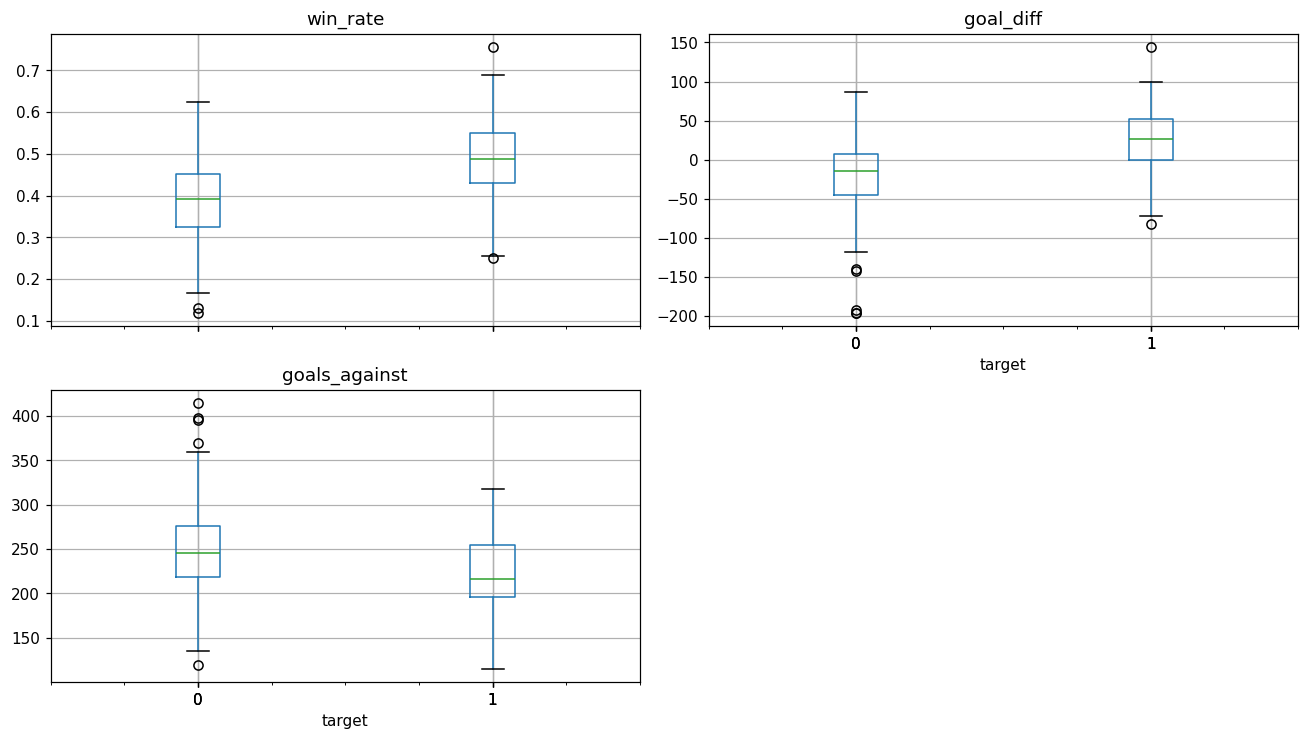

,team,year,win_rate,goal_diff,goals_against,future_win_rate,future_median,target
0,Boston Bruins,1990,0.550,35,264,0.450,0.444,1
1,Buffalo Sabres,1990,0.388,14,278,0.388,0.444,0
2,Calgary Flames,1990,0.575,81,263,0.388,0.444,0
3,Chicago Blackhawks,1990,0.613,73,211,0.450,0.444,1
4,Detroit Red Wings,1990,0.425,-25,298,0.537,0.444,1


In [12]:
features = ["win_rate", "goal_diff", "goals_against"]

# Средние и медианы для двух классов.
display(train.groupby("target")[features].agg(["mean", "median"]))

# Три графика.
train.boxplot(column=features, by="target", figsize=(12, 7), sharey=False)
plt.suptitle("")
plt.tight_layout()
plt.show()

# Примеры команд и сезонов.
display(train[["team", "year"] + features + ["future_win_rate", "future_median", "target"]].head())

**Ответ 3.2:**

Анализ проведён на train.

1. У команд с `target = 1` средняя текущая доля побед выше: **0.485 против 0.387**, медиана — **0.488 против 0.392**. График `win_rate` подтверждает различие, но распределения пересекаются: показатель не гарантирует будущий успех.

2. Средняя разница голов у будущего класса 1 — **+23.23**, у класса 0 — **−22.33**; медианы — **+27 и −14**. График `goal_diff` поддерживает ожидаемую связь. Однако разница голов связана с текущей долей побед, поэтому её дополнительную пользу нужно проверить моделью.

3. Команды будущего класса 1 в среднем пропускают меньше голов: **222.80 против 247.20**; медианы — **216.5 и 246**. На графике `goals_against` виден сдвиг распределения. Ограничение: абсолютное число голов зависит также от количества матчей и особенностей сезона.

Конкретное исключение — **Calgary Flames в 1990 году**: `win_rate = 0.575`, `goal_diff = +81`, но в 1991 году доля побед составила **0.388**, ниже медианы **0.444**, поэтому `target = 0`.

Все три показателя рассматриваются как кандидаты в признаки. Найденные связи относятся к train и не доказывают причинность.

## Раздел 4. Модели и эксперименты: 25 баллов

### 4.1. Постройте ориентиры

На train обучите простой константный baseline и оцените его на validation.
Отдельно используйте текущий `win_rate` как простую оценку для ранжирования
будущего класса. Посчитайте ROC-AUC обоих ориентиров и объясните,
какую планку задаёт каждый из них для обучаемой модели.

In [13]:
baseline = DummyClassifier(strategy="prior")
baseline.fit(train[["win_rate"]], train["target"])

constant_scores = baseline.predict_proba(validation[["win_rate"]])[:, 1]

print("ROC-AUC константного baseline:", roc_auc_score(validation["target"], constant_scores))
print("ROC-AUC текущего win_rate:", roc_auc_score(validation["target"], validation["win_rate"]))

ROC-AUC константного baseline: 0.5
ROC-AUC текущего win_rate: 0.756838905775076


**Ответ 4.1:**

Константный baseline обучен на train и выдаёт всем командам вероятность класса 1 около **0.491**. На validation его **ROC-AUC = 0.5**: он не различает команды и служит ориентиром отсутствия ранжирования.

Текущий `win_rate` без обучения даёт **ROC-AUC ≈ 0.757**. Значит, текущая доля побед полезна для ранжирования будущей успешности.

Для обучаемой модели важно сравнение с обоими ориентирами: превышение **0.5** показывает способность различать классы, а превышение **0.757** на validation — улучшение относительно простого использования текущего `win_rate`.

### 4.2. Постройте первую модель

Обучите логистическую регрессию. Самостоятельно выберите признаки и обоснуйте выбор.
Обработку пропусков и масштабирование включите в Pipeline и обучайте только на train.
Посчитайте ROC-AUC на validation и сравните с обоими ориентирами.
Объясните результат без использования test.

In [14]:
features = ["win_rate", "goal_diff", "goals_against"]

model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(train[features], train["target"])

probabilities = model.predict_proba(validation[features])[:, 1]
auc = roc_auc_score(validation["target"], probabilities)

print("ROC-AUC логистической регрессии:", auc)
print("ROC-AUC константного baseline:",
      roc_auc_score(validation["target"], constant_scores))
print("ROC-AUC текущего win_rate:",
      roc_auc_score(validation["target"], validation["win_rate"]))

ROC-AUC логистической регрессии: 0.7740628166160082
ROC-AUC константного baseline: 0.5
ROC-AUC текущего win_rate: 0.756838905775076


**Ответ 4.2:**

Для логистической регрессии выбраны `win_rate`, `goal_diff` и `goals_against`: они известны после текущего сезона, а анализ train показал их связь с будущей успешностью.

Заполнение пропусков медианой, масштабирование и классификатор объединены в Pipeline. Все этапы обучены только на train.

На validation получены:
- Логистическая регрессия — **ROC-AUC = 0.7741**.
- Константный baseline — **0.5000**.
- Текущий `win_rate` — **0.7568**.

Модель лучше обоих ориентиров. Прирост относительно `win_rate` составляет **0.0172**, что указывает на небольшое улучшение ранжирования за счёт совместного использования признаков. Устойчивость этого улучшения пока не проверена; test не использовался.

### 4.3. Проведите собственный эксперимент

Выберите одно осмысленное изменение: состав признаков, способ обработки данных,
параметры или другой алгоритм. До запуска запишите ожидаемый эффект и его причину.
Изменяйте одну понятную часть решения, сравните варианты на validation
и зафиксируйте выбор финальной модели до просмотра test.
Дополнительные эксперименты допустимы, но их количество само по себе не оценивается.

**Гипотеза эксперимента.** Добавление квадрата `win_rate` может улучшить ROC-AUC: связь текущей доли побед с логарифмом шансов будущего успеха может быть нелинейной. Меняется только состав признаков; обработка и параметры остаются прежними. Варианты сравниваются по ROC-AUC на validation.

*При доработке формулировка перенесена из исходного ответа перед кодом. Этот перенос не подтверждает, что гипотеза была записана до первоначального запуска.*


In [15]:
train = train.copy()
validation = validation.copy()

train["win_rate_squared"] = train["win_rate"] ** 2
validation["win_rate_squared"] = validation["win_rate"] ** 2

features_alt = features + ["win_rate_squared"]
model_alt = clone(model)
model_alt.fit(train[features_alt], train["target"])

scores = model_alt.predict_proba(validation[features_alt])[:, 1]
auc_alt = roc_auc_score(validation["target"], scores)

print("Исходная модель:", auc)
print("С квадратом win_rate:", auc_alt)

final_model = model_alt
final_features = features_alt

Исходная модель: 0.7740628166160082
С квадратом win_rate: 0.7745694022289767


**Ответ 4.3:**

В качестве эксперимента добавлен один новый признак — **квадрат `win_rate`**. Обработка данных и параметры модели остались прежними.

ROC-AUC на validation вырос с **0.77406 до 0.77457**. Прирост составил **0.00051**: он небольшой и не доказывает устойчивого преимущества.

По критерию большего ROC-AUC на validation выбрана логистическая регрессия с признаками `win_rate`, `goal_diff`, `goals_against`, `win_rate_squared`. Выбор зафиксирован **до просмотра test**.

## Раздел 5. Итоговая оценка и анализ ошибок: 15 баллов

### 5.1. Проведите итоговую оценку

Зафиксируйте выбранную модель, признаки и параметры, затем один раз оцените её на test.
Покажите ROC-AUC, F1 и accuracy при пороге 0.5 для выбранной модели
и сопоставимых baseline. Объясните различия между метриками и сравните
результаты validation и test. После этого не меняйте выбранное решение.

In [16]:
test = test.copy()
test["win_rate_squared"] = test["win_rate"] ** 2

# Один раз получаем прогноз выбранной модели на test.
test_scores = final_model.predict_proba(test[final_features])[:, 1]

# Сопоставимые ориентиры.
constant_test = baseline.predict_proba(test[["win_rate"]])[:, 1]
win_rate_test = test["win_rate"].to_numpy()

for name, scores in [
    ("Финальная модель", test_scores),
    ("Константный baseline", constant_test),
    ("Текущий win_rate", win_rate_test)
]:
    predictions = (scores >= 0.5).astype(int)

    print(name)
    print("ROC-AUC:", roc_auc_score(test["target"], scores))
    print("F1:", f1_score(test["target"], predictions, zero_division=0))
    print("Accuracy:", accuracy_score(test["target"], predictions))
    print()

Финальная модель
ROC-AUC: 0.7548125633232017
F1: 0.7058823529411765
Accuracy: 0.6629213483146067

Константный baseline
ROC-AUC: 0.5
F1: 0.0
Accuracy: 0.5280898876404494

Текущий win_rate
ROC-AUC: 0.7403748733535969
F1: 0.6521739130434783
Accuracy: 0.6404494382022472



**Ответ 5.1:**

До просмотра test выбрана логистическая регрессия с признаками `win_rate`, `goal_diff`, `goals_against`, `win_rate_squared`. В Pipeline включены заполнение пропусков медианой и стандартизация; `max_iter=1000`, остальные параметры классификатора — по умолчанию. Модель обучена на train.

На test получены следующие результаты при пороге **0.5**:

- **Финальная модель:** ROC-AUC — **0.7548**, F1 — **0.7059**, accuracy — **0.6629**.
- **Константный baseline:** ROC-AUC — **0.5000**, F1 — **0**, accuracy — **0.5281**.
- **Текущий `win_rate`:** ROC-AUC — **0.7404**, F1 — **0.6522**, accuracy — **0.6404**.

Модель превзошла оба ориентира по всем трём метрикам. ROC-AUC оценивает ранжирование без фиксированного порога; F1 сочетает точность и полноту класса 1; accuracy показывает долю правильных ответов.

Константный baseline выдаёт вероятность около 0.491 и при пороге 0.5 предсказывает всем класс 0. Поэтому его F1 равен нулю, а accuracy соответствует доле класса 0.

ROC-AUC модели снизился с **0.7746 на validation до 0.7548 на test**. На более поздних сезонах качество оказалось немного ниже; причины этого снижения отдельно не установлены. После итоговой оценки модель и признаки не изменялись.

**Матрица ошибок финальной модели на всём test (порог 0.5).**


,Прогноз: 0,Прогноз: 1
Факт: 0,23,24
Факт: 1,6,36


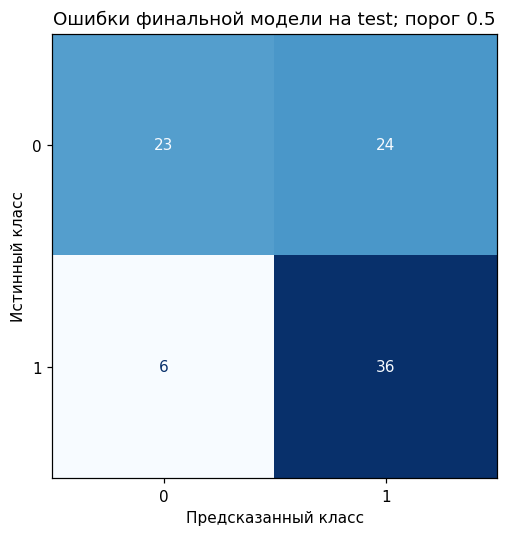

Верно: класс 0 — 23, класс 1 — 36. Ошибки: FP = 24, FN = 6.
Всего ошибок: 30 из 89; precision = 0.600; recall = 0.857.


In [17]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Используем уже полученные test_scores, не переобучая модель.
test_predictions = (test_scores >= 0.5).astype(int)
cm = confusion_matrix(test["target"], test_predictions, labels=[0, 1])
display(pd.DataFrame(cm, index=["Факт: 0", "Факт: 1"],
                     columns=["Прогноз: 0", "Прогноз: 1"]))
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=[0, 1]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Ошибки финальной модели на test; порог 0.5")
ax.set_xlabel("Предсказанный класс")
ax.set_ylabel("Истинный класс")
plt.tight_layout()
plt.show()
tn, fp, fn, tp = cm.ravel()
print(f"Верно: класс 0 — {tn}, класс 1 — {tp}. Ошибки: FP = {fp}, FN = {fn}.")
print(f"Всего ошибок: {fp + fn} из {cm.sum()}; precision = {tp / (tp + fp):.3f}; recall = {tp / (tp + fn):.3f}.")


Верно предсказаны 23 команды класса 0 и 36 команд класса 1. Всего 30 ошибок из 89: 24 ложноположительных и 6 ложноотрицательных. На этом test модель чаще ошибочно прогнозирует успех, чем пропускает успешные команды. Precision класса 1 — 0.600, recall — 0.857. Разбор четырёх уверенных ошибок в разделе 5.2 дополняет эту общую картину.


### 5.2. Разберите ошибки

Выберите от трёх до пяти ошибок финальной модели по явно указанному принципу.
Это могут быть наиболее уверенные ошибки, отдельный тип ошибки или другой
обоснованный набор. Покажите идентификаторы строк, вероятности и значения,
необходимые для анализа. Найдите общие черты и различия; отделите факты
из таблицы от гипотез и назовите данные, нужные для проверки одной гипотезы.

In [18]:
results = test.copy()
results["probability"] = test_scores
results["prediction"] = (results["probability"] >= 0.5).astype(int)

errors = results[results["prediction"] != results["target"]].copy()

# Чем дальше вероятность от 0.5, тем увереннее прогноз.
errors["confidence"] = abs(errors["probability"] - 0.5)
errors = errors.sort_values("confidence", ascending=False).head(4)

display(errors[[
    "team", "year", "target_year",
    "win_rate", "goal_diff", "goals_against",
    "future_win_rate", "future_median",
    "probability", "prediction", "target"
]])

,team,year,target_year,win_rate,goal_diff,goals_against,future_win_rate,future_median,probability,prediction,target
464,Boston Bruins,2008,2009,0.646,78,196,0.476,0.488,0.924751,1,0
514,Phoenix Coyotes,2009,2010,0.610,23,202,0.524,0.524,0.837595,1,0
509,New Jersey Devils,2009,2010,0.585,31,191,0.463,0.524,0.819059,1,0
535,Los Angeles Kings,2010,2011,0.561,21,198,0.488,0.500,0.766660,1,0


**Ответ 5.2:**

Выбраны четыре самые уверенные ошибки: ошибочные прогнозы с наибольшим расстоянием вероятности от порога 0.5. Все четыре — **ложноположительные**: модель предсказала класс 1, фактически получен класс 0.

- **Boston Bruins, 2008 → 2009:** вероятность **0.925**, будущий `win_rate = 0.476` ниже медианы **0.488**.
- **Phoenix Coyotes, 2009 → 2010:** вероятность **0.838**, будущий `win_rate = 0.524` равен медиане **0.524**. По строгому условию задания это класс 0.
- **New Jersey Devils, 2009 → 2010:** вероятность **0.819**, будущий `win_rate = 0.463` ниже медианы **0.524**.
- **Los Angeles Kings, 2010 → 2011:** вероятность **0.767**, будущий `win_rate = 0.488` ниже медианы **0.500**.

Общие черты: текущая доля побед всех команд выше 0.5, разница голов положительная, пропущено от 191 до 202 голов. Несмотря на хорошие текущие показатели, будущие результаты не превысили медиану. При этом у Phoenix доля побед снизилась меньше и оказалась точно на границе классов.

**Гипотеза:** снижение результатов могло быть связано с изменениями состава или травмами. Таблица этого не подтверждает; для проверки нужны сведения о переходах игроков и пропущенных ими матчах между сезонами.

Эти четыре примера не представляют все ошибки модели. После анализа модель не изменялась.

## Раздел 6. Выводы и воспроизводимость: 5 баллов

### 6.1. Сформулируйте выводы

Сформулируйте основные выводы и ограничения работы со ссылками на свои графики,
строки и метрики. Опишите минимум два решения, которые вы изменили
или подтвердили после получения результатов. Назовите одно улучшение,
которое вы сознательно не стали выполнять, и объясните причину.
Убедитесь, что последовательность работы и финальные параметры можно воспроизвести.

**Ответ 6.1:**

По анализу train команды, успешные в следующем сезоне, имеют в среднем более высокие текущие `win_rate` и `goal_diff` и более низкий `goals_against`. Это подтверждают числовые сводки и boxplot из раздела 3.2. Однако распределения пересекаются, поэтому хорошие текущие показатели не гарантируют будущую успешность.

Финальная модель — логистическая регрессия с признаками `win_rate`, `goal_diff`, `goals_against`, `win_rate_squared`. Pipeline включает заполнение пропусков медианой и стандартизацию; `max_iter=1000`, остальные параметры — по умолчанию. Все этапы обучены только на train.

На test получены **ROC-AUC = 0.7548, F1 = 0.7059 и accuracy = 0.6629** при пороге 0.5. Модель превзошла константный baseline и текущий `win_rate`. При этом ROC-AUC снизился относительно validation, где составлял **0.7746**.

После получения результатов приняты два решения:

- Подтверждён выбор текущих показателей как признаков: их совместное использование дало ROC-AUC **0.7741**, выше ориентира `win_rate` — **0.7568** на validation.
- Добавлен квадрат `win_rate`: ROC-AUC вырос до **0.7746**. Улучшение небольшое, его устойчивость не доказана.

Разбор ошибок в 5.2 показал, что даже сильные текущие результаты могут смениться более слабыми. Например, для Boston Bruins в сезоне 2008 модель выдала вероятность **0.925**, но в 2009 году доля побед оказалась ниже медианы. Для Phoenix Coyotes будущая доля побед равнялась медиане, поэтому по строгому условию получен класс 0.

Ограничения работы: небольшой объём данных, повторные наблюдения одних команд, различия между сезонами и отсутствие сведений о составе и травмах. Связи в данных не доказывают причинность, а небольшие различия метрик могут быть неустойчивыми.

Сознательно не выполнялся широкий подбор гиперпараметров, чтобы ограничить подстройку под небольшую validation. После оценки на test решение не менялось.

Для воспроизведения используются сохранённый `data/hockey_raw.csv`, последовательное выполнение ячеек и фиксированные временные границы: train — до 2005 года целевого сезона, validation — 2006–2008, test — 2009–2011.